# Dataset V0 - Analyzing Human Validator Scores per Topic and Community
## June 29




The goal of this notebook is to analyse the available human scores available in the V0 version riddles dataset (43 communities).

The targeted columns are:
- `Human Validator Name`
- `Human Answer (Original)`
- `Rating of Human Answer (0-2)`

Two things to note is that the scaling among the communities is not the same → firstly it needs to be normalized. The other thing is that filling these columns were not required → these values are null (`Nan`) for most communities.

p.s. All figures use the shared project style in `analysis/style.py`, so they match the rest of the paper.

# Import Libraries & Modules

In [3]:
import os
import pandas as pd
import numpy as np

import zipfile

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import sys

# Load Plot Styles

You need to put *style.py* file in analysis folder:

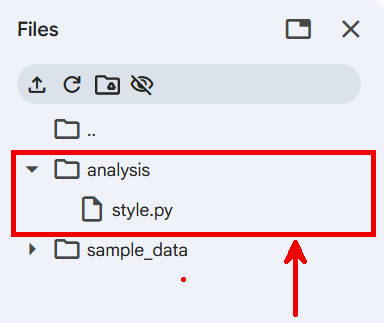

In [18]:
# Make the shared plotting style importable no matter where this notebook is run from.
def find_repo_root(start: Path) -> Path:
    """Walk upward until we find analysis/style.py — that folder is the repo root."""
    for folder in [start, *start.parents]:
        if (folder / "analysis" / "style.py").exists():
            return folder
    raise FileNotFoundError(f"Could not find analysis/style.py above {start}")


REPO_ROOT = find_repo_root(Path.cwd())
sys.path.insert(0, str(REPO_ROOT))


from analysis.style import apply_style, register_fonts, save_figure, PALETTE, CATEGORICAL_CYCLE
register_fonts()   # use vendored fonts if any exist (none yet) — harmless otherwise
apply_style()      # serif "LaTeX-paper" look + colorblind-safe palette

# Load Dataset

**TODO**

Replace with downloading directly from Google drive/Huggingface.

In [6]:

with zipfile.ZipFile('/content/Riddles-V0.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/Riddles-V0')


In [7]:
def load_riddles_dataframes(extracted_files_dir):
    riddles_dataframes = {}
    for root, dirs, files in os.walk(extracted_files_dir):
        for file_name in files:
            file_path = os.path.join(root, file_name)

            if file_name.endswith('.xlsx'):
                try:
                    df_riddles = pd.read_excel(file_path, sheet_name='Riddles')
                    riddles_dataframes[file_name] = df_riddles
                    print(f"Loaded 'Riddles' sheet from {file_name}")
                except Exception as e:
                    print(f"Error loading 'Riddles' sheet from {file_name}: {e}")
            elif file_name.endswith('.csv'):
                try:
                    df_csv = pd.read_csv(file_path)
                    riddles_dataframes[file_name] = df_csv
                    print(f"Loaded CSV file: {file_name}")
                except Exception as e:
                    print(f"Error loading CSV file {file_name}: {e}")

    print(f"\nSuccessfully loaded {len(riddles_dataframes)} files/sheets.")
    return riddles_dataframes

# replace the path with your own, I'm running from colab root...
extracted_files_dir = '/content/Riddles-V0/v0 - due May 29'
riddles_dataframes = load_riddles_dataframes(extracted_files_dir)


Loaded 'Riddles' sheet from Cultural Riddles Benchmark [Thai_Thailand].xlsx
Loaded 'Riddles' sheet from Cultural Riddles Benchmark [Arabic_Egypt].xlsx
Loaded 'Riddles' sheet from Cultural Riddles Benchmark [Arabic_Morocco].xlsx
Loaded 'Riddles' sheet from Cultural Riddles Benchmark [Chinese_China].xlsx
Loaded 'Riddles' sheet from Cultural Riddles Benchmark [German_Germany].xlsx
Loaded 'Riddles' sheet from Cultural Riddles Benchmark [Sinhala_Sri Lanka].xlsx
Loaded 'Riddles' sheet from Cultural Riddles Benchmark [Spanish_Cuba].xlsx
Loaded 'Riddles' sheet from Cultural Riddles Benchmark [English_Canada].xlsx
Loaded 'Riddles' sheet from Cultural Riddles Benchmark [Tamil_India].xlsx
Loaded 'Riddles' sheet from Cultural Riddles Benchmark [Chinese (Simplified)_China].xlsx
Loaded 'Riddles' sheet from Cultural Riddles Benchmark [Dutch_Netherlands].xlsx
Error loading 'Riddles' sheet from Cultural Riddles Benchmark [Luganda_Uganda].xlsx: Worksheet named 'Riddles' not found
Loaded 'Riddles' sheet 

In [9]:
def display_riddle_dataframe_head(riddles_dataframes, sheet_index):
  """
  sheet_index should be between 0~42 for V0.
  """
  if not riddles_dataframes:
      print("No dataframes were loaded.")
      return

  keys = list(riddles_dataframes.keys())
  if 0 <= sheet_index < len(keys):
      selected_key = keys[sheet_index]
      print(f"\nDisplaying head of '{selected_key}' (Sheet Index: {sheet_index}):")
      display(riddles_dataframes[selected_key].head())
  else:
      print(f"Invalid sheet index: {sheet_index}. Please provide an index between 0 and {len(keys) - 1}.")


display_riddle_dataframe_head(riddles_dataframes, sheet_index=40)


Displaying head of 'Cultural Riddles Benchmark [Marathi_India].xlsx' (Sheet Index: 40):


,Number,Topic,Author,Riddle (Original Language),Riddle (English Translation),Hints (Optional),"Comments (Optional), e.g. about region/generation-specificity",Reference Answer (Original),Reference Answer (English),Human Validator Name,Human Answer (Original),Rating of Human Answer (0-2),Comment (Optional) about evaluation of human answer
0,1.0,Politics,Rushikesh Zawar and Yash Bagla,"लाल आहे पण रंग नाही, कृष्ण आहे पण देव नाही, आड...","It is 'Lal' but not a color, 'Krishna' but not...",NaN,NaN,लालकृष्ण अडवाणी.,Lal Krishna Advani,NaN,NaN,NaN,NaN
1,2.0,Politics,Rushikesh Zawar and Yash Bagla,"दोन घरांत माझी चर्चा चालते; एक जनतेचा आवाज, दु...",My discussions take place in two houses; one i...,NaN,NaN,महाराष्ट्र विधिमंडळ,NaN,NaN,NaN,NaN,NaN
2,3.0,Politics,Rushikesh Zawar and Yash Bagla,"इंजिनशिवाय, चाकांशिवाय चालणारी कार?","A 'car' that runs without an engine, without w...",NaN,NaN,सरकार,NaN,NaN,NaN,NaN,NaN
3,4.0,Politics,Rushikesh Zawar and Yash Bagla,"मी राजा नाही, पण राज्याचा घटनात्मक प्रमुख; माझ...","I am not a king, but the constitutional head o...",NaN,NaN,राज्यपाल,NaN,NaN,NaN,NaN,NaN
4,5.0,Politics,Rushikesh Zawar and Yash Bagla,"गाव, शहर, पंचायत, पालिका यांची स्पर्धा मी बघतो...","I watch the competition between villages, citi...",NaN,NaN,मतदान,NaN,NaN,NaN,NaN,NaN


# Number of null cells per Column and Community

**TODO**

Null values in reference answers should be checked..

In [10]:
def print_null_counts_per_community(riddles_dataframes):
  """
  Return the column names + number of null cells from each loaded dataframe
  """
  if not riddles_dataframes:
      print("No dataframes available to analyze for nulls.")
      return

  for file_name, df in riddles_dataframes.items():
      print(f"\nCommunity: {file_name}")
      null_counts = df.isnull().sum()
      if null_counts.sum() == 0:
          print("  No null values in this community.")
      else:
          for col, count in null_counts.items():
              if count > 0:
                  print(f"  Column '{col}': {count} null values")


print_null_counts_per_community(riddles_dataframes)



Community: Cultural Riddles Benchmark [Thai_Thailand].xlsx
  Column 'Hints (Optional)': 76 null values
  Column 'Comments (Optional), e.g. about region/generation-specificity': 99 null values
  Column 'Human Answer (Original)': 1 null values
  Column 'Comment (Optional) about evaluation of human answer': 98 null values

Community: Cultural Riddles Benchmark [Arabic_Egypt].xlsx
  Column 'Hints (Optional)': 100 null values
  Column 'Comments (Optional), e.g. about region/generation-specificity': 100 null values
  Column 'Human Validator Name': 1 null values
  Column 'Comment (Optional) about evaluation of human answer': 100 null values

Community: Cultural Riddles Benchmark [Arabic_Morocco].xlsx
  Column 'Hints (Optional)': 100 null values
  Column 'Comments (Optional), e.g. about region/generation-specificity': 100 null values
  Column 'Human Validator Name': 21 null values
  Column 'Human Answer (Original)': 21 null values
  Column 'Rating of Human Answer (0-2)': 21 null values
  Colu

In [11]:
columns_to_check = [
    'Human Validator Name',
    'Human Answer (Original)',
    'Rating of Human Answer (0-2)'
]

def analyze_non_nan_columns(riddles_dataframes, columns_to_check):
  """
  More specific function to check if all specified columns (given as input) have non-NaN content.
  """
  count_dataframes_with_non_nan = 0

  for file_name, df in riddles_dataframes.items():
      if all(col in df.columns for col in columns_to_check):
          has_non_nan_in_all_columns = True
          for col in columns_to_check:
              if df[col].isnull().all():
                  has_non_nan_in_all_columns = False
                  break

          if has_non_nan_in_all_columns:
              count_dataframes_with_non_nan += 1
              print(f"DataFrame '{file_name}' has non-NaN content in all specified columns.")
      else:
          missing_cols = [col for col in columns_to_check if col not in df.columns]
          print(f"DataFrame '{file_name}' is missing columns: {missing_cols}")

  print(f"\nTotal dataframes with non-NaN content in all three specified columns: {count_dataframes_with_non_nan}")
  return count_dataframes_with_non_nan


analyze_non_nan_columns(riddles_dataframes, columns_to_check)

DataFrame 'Cultural Riddles Benchmark [Thai_Thailand].xlsx' is missing columns: ['Rating of Human Answer (0-2)']
DataFrame 'Cultural Riddles Benchmark [Arabic_Egypt].xlsx' has non-NaN content in all specified columns.
DataFrame 'Cultural Riddles Benchmark [Arabic_Morocco].xlsx' has non-NaN content in all specified columns.
DataFrame 'Cultural Riddles Benchmark [English_Canada].xlsx' has non-NaN content in all specified columns.
DataFrame 'Cultural Riddles Benchmark [Tamil_India].xlsx' has non-NaN content in all specified columns.
DataFrame 'Cultural Riddles Benchmark [Chinese (Simplified)_China].xlsx' has non-NaN content in all specified columns.
DataFrame 'Cultural Riddles Benchmark [Dutch_Netherlands].xlsx' has non-NaN content in all specified columns.
DataFrame 'Cultural Riddles Benchmark [Nepali_Nepal].xlsx' is missing columns: ['Rating of Human Answer (0-2)']
DataFrame 'Cultural Riddles Benchmark [Bengali_India].xlsx' has non-NaN content in all specified columns.
DataFrame 'Cultur

19

In [12]:
column_for_analysis = 'Rating of Human Answer (0-2)'

def analyze_rating_column(riddles_dataframes, column_for_analysis):
    """Analyzes and prints value counts for a specified column across multiple dataframes."""
    for file_name, df in riddles_dataframes.items():
        if column_for_analysis in df.columns:
            print(f"Analysis for DataFrame: {file_name}")
            print(df[column_for_analysis].value_counts(dropna=False))
            print("\n")
        else:
            print(f"DataFrame '{file_name}' does not contain the column '{column_for_analysis}'.\n")


analyze_rating_column(riddles_dataframes, column_for_analysis)


DataFrame 'Cultural Riddles Benchmark [Thai_Thailand].xlsx' does not contain the column 'Rating of Human Answer (0-2)'.

Analysis for DataFrame: Cultural Riddles Benchmark [Arabic_Egypt].xlsx
Rating of Human Answer (0-2)
2: correct              91
0: completely wrong      6
1: partially correct     3
Name: count, dtype: int64


Analysis for DataFrame: Cultural Riddles Benchmark [Arabic_Morocco].xlsx
Rating of Human Answer (0-2)
2: correct              60
NaN                     21
0: completely wrong     15
1: partially correct     4
Name: count, dtype: int64


Analysis for DataFrame: Cultural Riddles Benchmark [Chinese_China].xlsx
Rating of Human Answer (0-2)
NaN    100
Name: count, dtype: int64


Analysis for DataFrame: Cultural Riddles Benchmark [German_Germany].xlsx
Rating of Human Answer (0-2)
NaN    100
Name: count, dtype: int64


Analysis for DataFrame: Cultural Riddles Benchmark [Sinhala_Sri Lanka].xlsx
Rating of Human Answer (0-2)
NaN    100
Name: count, dtype: int64


Analysi

# Rating Distribution

Normalization function

In [13]:
column_for_analysis = 'Rating of Human Answer (0-2)'

def map_rating_to_numeric(rating_str):
    if pd.isna(rating_str):
        return pd.NA
    rating_str = str(rating_str).strip().lower()
    if '0:' in rating_str or 'completely wrong' in rating_str:
        return 0
    elif '1:' in rating_str or 'partially correct' in rating_str or 'somewhat close' in rating_str:
        return 1
    elif '2:' in rating_str or '3:' in rating_str or 'correct' in rating_str:
        return 2
    elif "i don't know" in rating_str:
        return pd.NA
    else:
        return pd.NA

Processing: Cultural Riddles Benchmark [Arabic_Egypt].xlsx


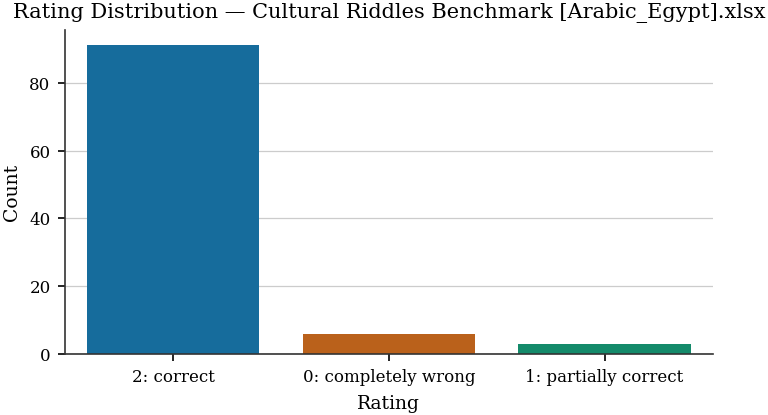

  Average ratings per topic in 'Cultural Riddles Benchmark [Arabic_Egypt].xlsx':
Topic
Arts                 2.0
History              2.0
Kid's World          2.0
Sports               1.9
National Heritage    1.8
Food culture         1.8
Politics             1.8
Geography            1.8
Economics            1.7
Everyday Life        1.7

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Arabic_Morocco].xlsx


/tmp/ipykernel_3123/3989376659.py:24: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  sns.barplot(


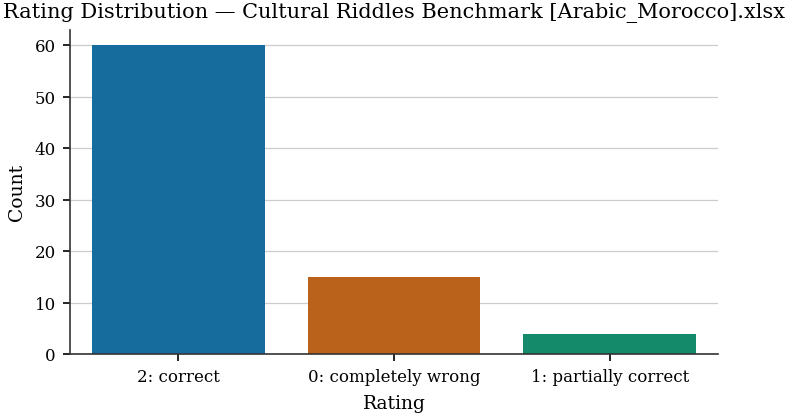

/tmp/ipykernel_3123/3989376659.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["Numeric_Rating"] = df_clean["Numeric_Rating"].astype(int)
/tmp/ipykernel_3123/3989376659.py:24: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  sns.barplot(


  Average ratings per topic in 'Cultural Riddles Benchmark [Arabic_Morocco].xlsx':
Topic
Politics             2.000000
Everyday Life        2.000000
Kid's World          1.857143
Clothing             1.666667
Food                 1.600000
Geography            1.555556
National Heritage    1.500000
History              1.428571
Arts                 1.250000
Sports               0.857143

--------------------------------------------------

Processing: Cultural Riddles Benchmark [English_Canada].xlsx


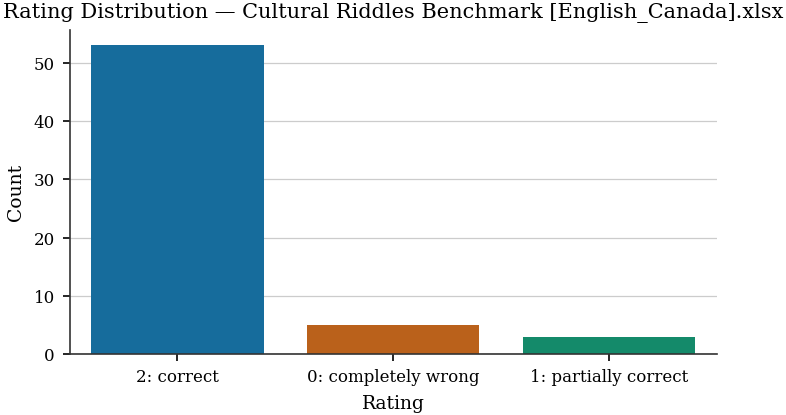

/tmp/ipykernel_3123/3989376659.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["Numeric_Rating"] = df_clean["Numeric_Rating"].astype(int)


  Average ratings per topic in 'Cultural Riddles Benchmark [English_Canada].xlsx':
Topic
Everyday Life        2.000000
Nature               2.000000
Sports               2.000000
Kid's World          2.000000
Arts                 1.800000
History              1.714286
Food                 1.666667
Geography            1.428571
National Heritage    1.333333

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Tamil_India].xlsx


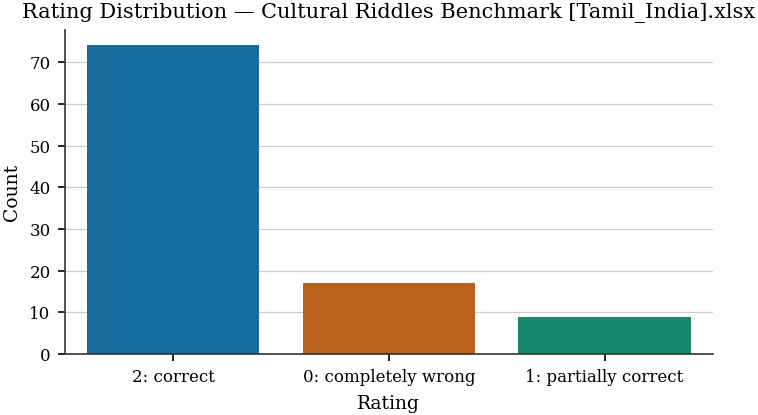

  Average ratings per topic in 'Cultural Riddles Benchmark [Tamil_India].xlsx':
Topic
Geography                        2.0
Arts                             1.8
Politics                         1.8
History                          1.8
Everyday Life                    1.5
Sports                           1.5
Wildcard 1 [Tamil Literature]    1.4
Wildcard 2 [Food Is Medicine]    1.4
National Heritage                1.3
Kid's World                      1.2

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Chinese (Simplified)_China].xlsx


/tmp/ipykernel_3123/3989376659.py:24: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  sns.barplot(


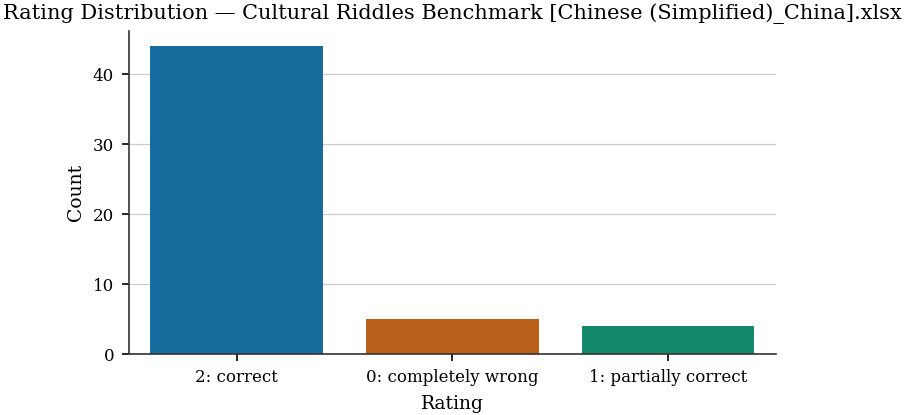

/tmp/ipykernel_3123/3989376659.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["Numeric_Rating"] = df_clean["Numeric_Rating"].astype(int)


  Average ratings per topic in 'Cultural Riddles Benchmark [Chinese (Simplified)_China].xlsx':
Topic
Arts                 2.000
Everyday Life        2.000
Sports               2.000
Geography            2.000
Politics             2.000
Kid's World          2.000
Animal               1.800
Food                 1.625
National Heritage    1.625
History              0.500

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Dutch_Netherlands].xlsx


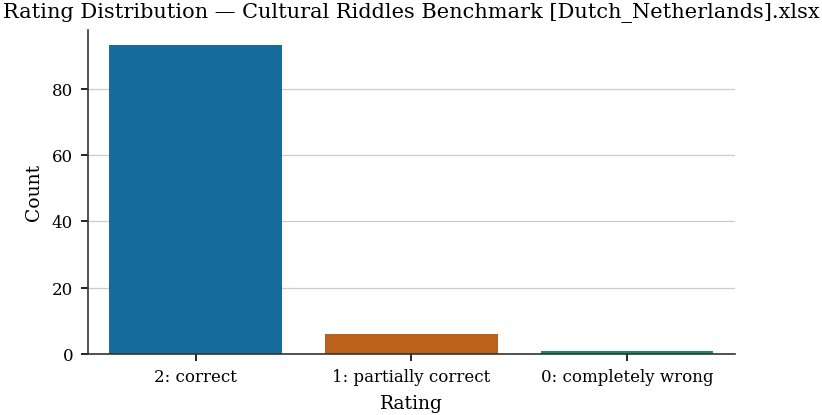

  Average ratings per topic in 'Cultural Riddles Benchmark [Dutch_Netherlands].xlsx':
Topic
Geography            2.0
Food                 2.0
Kid's World          2.0
National Heritage    2.0
History              1.9
Arts                 1.9
Sports               1.9
Politics             1.9
Everyday Life        1.8
Work life            1.8

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Arabic_Sudan].xlsx


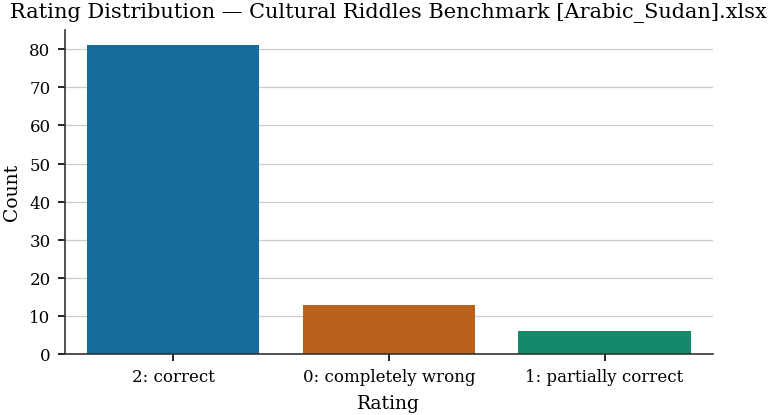

  Average ratings per topic in 'Cultural Riddles Benchmark [Arabic_Sudan].xlsx':
Topic
Everyday Life        2.0
Sports               2.0
Food                 1.9
National Heritage    1.8
Proverbs             1.8
Arts                 1.7
Geography            1.6
History              1.6
Kid's World          1.5
Politics             0.9

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Bengali_India].xlsx


/tmp/ipykernel_3123/3989376659.py:24: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(


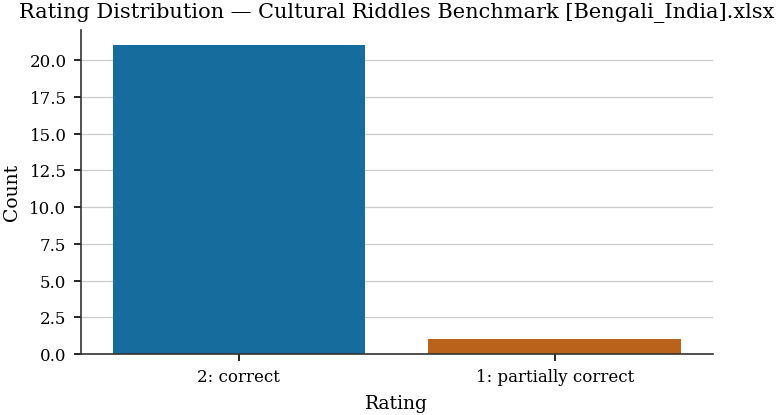

/tmp/ipykernel_3123/3989376659.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["Numeric_Rating"] = df_clean["Numeric_Rating"].astype(int)


  Average ratings per topic in 'Cultural Riddles Benchmark [Bengali_India].xlsx':
Topic
Anatomy              2.000000
Everyday Life        2.000000
Geography            2.000000
History              2.000000
Kid's World          2.000000
National Heritage    2.000000
Sports               2.000000
Nature               1.833333

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Arabic_Syria].xlsx


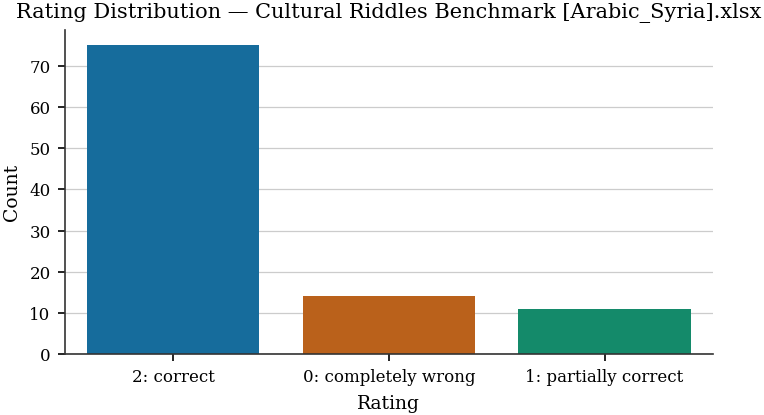

  Average ratings per topic in 'Cultural Riddles Benchmark [Arabic_Syria].xlsx':
Topic
Politics                       1.9
Kid's World                    1.9
Wildcard 1 [Food]              1.9
Everyday Life                  1.8
Arts                           1.7
National Heritage              1.7
Sports                         1.5
History                        1.4
Geography                      1.2
Wildcard 2 [animals_naming]    1.1

--------------------------------------------------

Processing: Cultural Riddles Benchmark [French_France].xlsx


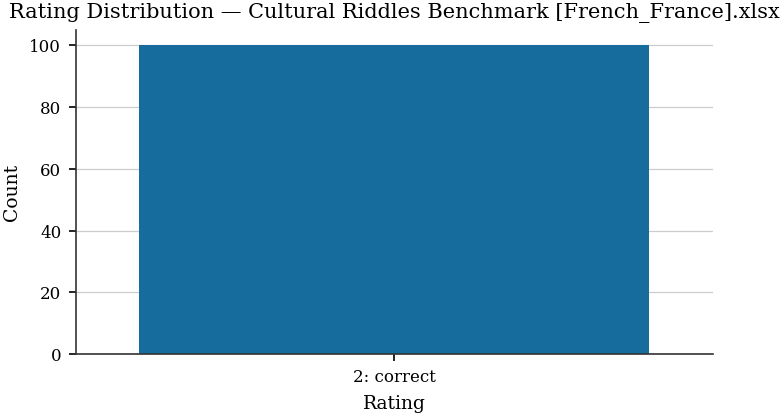

  Average ratings per topic in 'Cultural Riddles Benchmark [French_France].xlsx':
Topic
Arts                 2.0
Everyday Life        2.0
Geography            2.0
History              2.0
Kid's World          2.0
National Heritage    2.0
Politics             2.0
Science              2.0
Slang                2.0
Sports               2.0

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Italian_Italy].xlsx


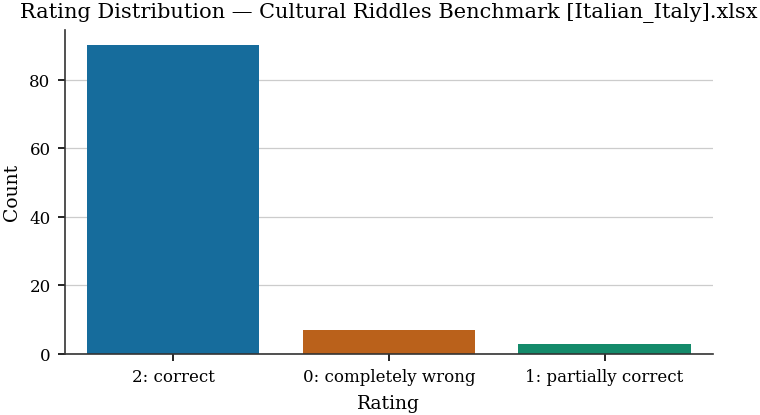

  Average ratings per topic in 'Cultural Riddles Benchmark [Italian_Italy].xlsx':
Topic
Everyday Life         2.0
Kid's World           2.0
Politics              2.0
National Heritage     2.0
Geography             1.9
Arts                  1.8
Proverbs & Sayings    1.8
Sports                1.7
History               1.6
Myths & Folklore      1.5

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Malayalam_India].xlsx


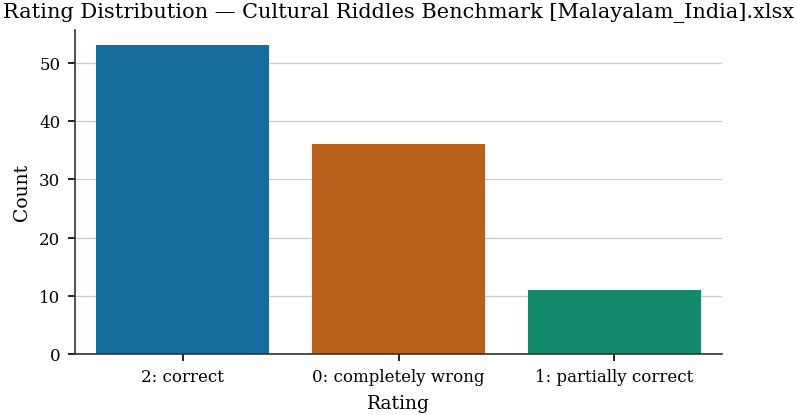

  Average ratings per topic in 'Cultural Riddles Benchmark [Malayalam_India].xlsx':
Topic
Kid's World          1.8
Geography            1.4
History              1.4
Everyday Life        1.3
Sports               1.2
National Heritage    1.1
Politics             1.0
Cinema               1.0
Nature               0.9
Arts                 0.6

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Spanish_Peru].xlsx


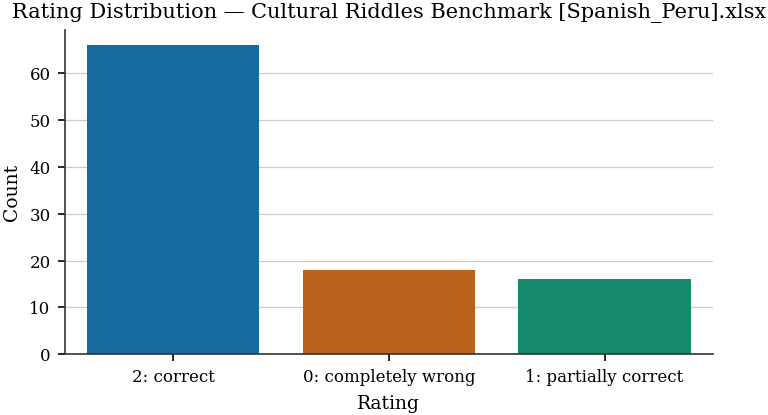

  Average ratings per topic in 'Cultural Riddles Benchmark [Spanish_Peru].xlsx':
Topic
Politics             2.0
Everyday Life        1.9
Kid's World          1.9
National Heritage    1.6
Geography            1.5
History              1.4
Arts                 1.3
Slang                1.1
Sports               1.1
Myths and Legends    1.0

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Persian_Iran].xlsx


/tmp/ipykernel_3123/3989376659.py:24: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  sns.barplot(


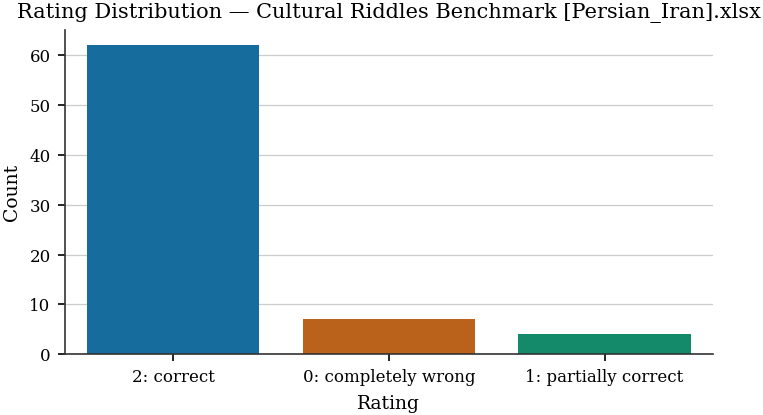

/tmp/ipykernel_3123/3989376659.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["Numeric_Rating"] = df_clean["Numeric_Rating"].astype(int)


  Average ratings per topic in 'Cultural Riddles Benchmark [Persian_Iran].xlsx':
Topic
Arts                 2.000000
Cinema               2.000000
Politics             2.000000
Kid's World          2.000000
Food                 1.875000
History              1.800000
Sports               1.714286
Everyday Life        1.666667
National Heritage    1.375000
Geography            1.000000

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Polish_Poland].xlsx


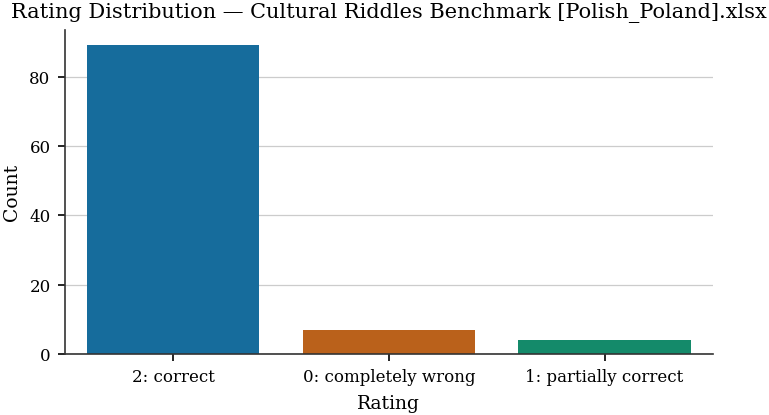

  Average ratings per topic in 'Cultural Riddles Benchmark [Polish_Poland].xlsx':
Topic
Kid's World          2.0
History              2.0
Popculture           2.0
Arts                 1.9
Everyday Life        1.8
Language             1.8
Sports               1.8
National Heritage    1.7
Geography            1.6
Politics             1.6

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Uzbek_Uzbekistan].xlsx


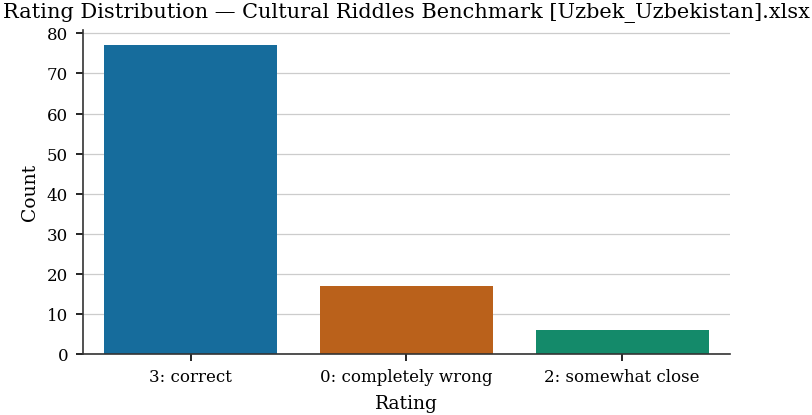

  Average ratings per topic in 'Cultural Riddles Benchmark [Uzbek_Uzbekistan].xlsx':
Topic
Kid's World          2.0
Geography            1.7
National Cuisine     1.7
Arts                 1.6
Culture              1.6
Politics             1.6
National Heritage    1.5
Sports               1.5
History              1.4
Everyday Life        1.4

--------------------------------------------------

Processing: Cultural Riddles Benchmark [English_USA].xlsx


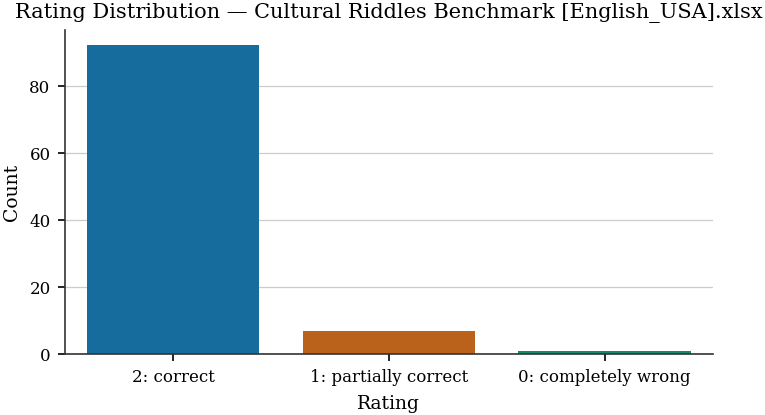

  Average ratings per topic in 'Cultural Riddles Benchmark [English_USA].xlsx':
Topic
Everyday Life        2.0
Geography            2.0
Politics             2.0
History              2.0
National Heritage    2.0
Arts                 1.9
Kid's World          1.9
Hollywood            1.9
Sports               1.9
TV shows             1.5

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Bengali_Bangladesh].xlsx


/tmp/ipykernel_3123/3989376659.py:24: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  sns.barplot(


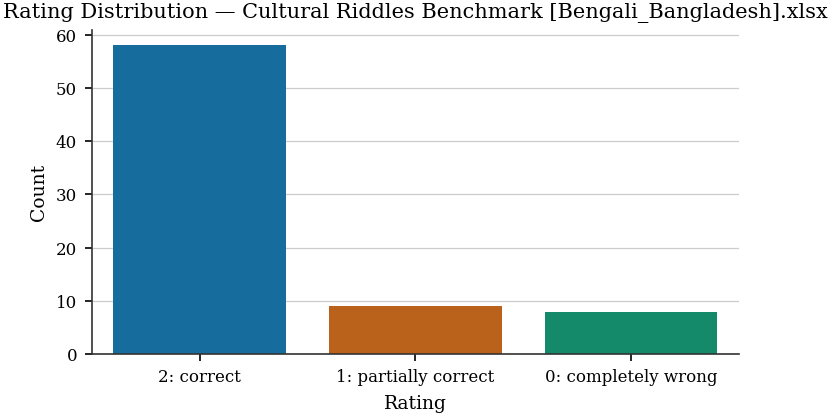

/tmp/ipykernel_3123/3989376659.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["Numeric_Rating"] = df_clean["Numeric_Rating"].astype(int)


  Average ratings per topic in 'Cultural Riddles Benchmark [Bengali_Bangladesh].xlsx':
Topic
National Heritage    2.000000
Sports               2.000000
Kid's World          1.888889
Politics             1.888889
Human Anatomy        1.857143
Geography            1.555556
Arts                 1.222222
Nature               1.200000
Everyday Life        1.000000
History              1.000000

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Russian_Russia].xlsx


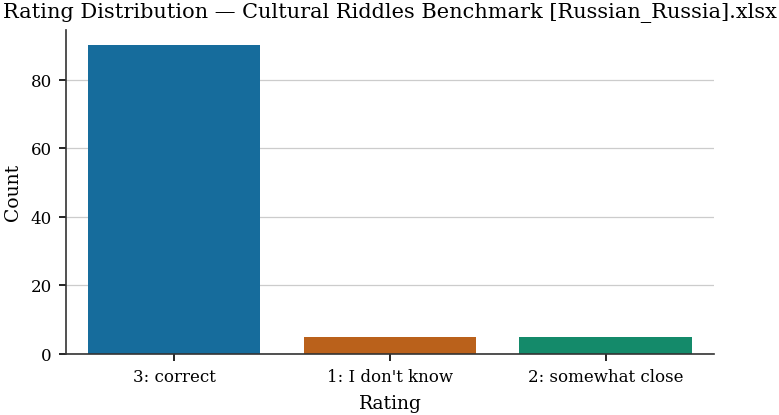

  Average ratings per topic in 'Cultural Riddles Benchmark [Russian_Russia].xlsx':
Topic
Arts                  2.0
National Heritage     2.0
Colloquial phrases    1.9
Everyday Life         1.9
Kid's World           1.9
Geography             1.9
Politics              1.9
Moscow                1.9
History               1.8
Sports                1.8

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Yoruba_Nigeria].xlsx


/tmp/ipykernel_3123/3989376659.py:24: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.barplot(


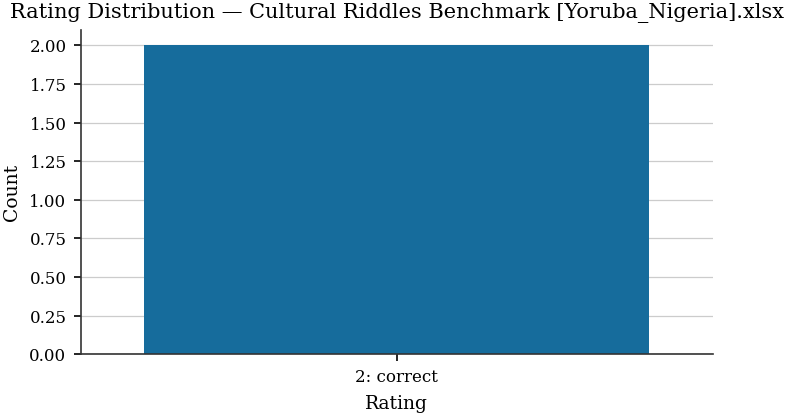

/tmp/ipykernel_3123/3989376659.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean["Numeric_Rating"] = df_clean["Numeric_Rating"].astype(int)
/tmp/ipykernel_3123/3989376659.py:24: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.barplot(


  Average ratings per topic in 'Cultural Riddles Benchmark [Yoruba_Nigeria].xlsx':
Topic
Everyday Life    2.0

--------------------------------------------------

Processing: Cultural Riddles Benchmark [Marathi_India].xlsx


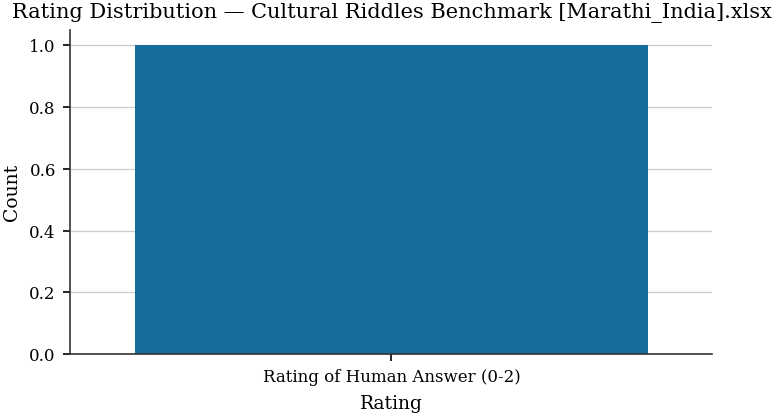

  No valid numeric ratings in 'Cultural Riddles Benchmark [Marathi_India].xlsx'. Skipping.


--------------------------------------------------



In [30]:
def analyze_and_plot_ratings_by_topic(riddles_dataframes, column_for_analysis, map_rating_to_numeric):
    filtered_dataframes = {
        file_name: df
        for file_name, df in riddles_dataframes.items()
        if column_for_analysis in df.columns and not df[column_for_analysis].isnull().all()
    }

    if not filtered_dataframes:
        print("No dataframes found with non-NaN content for analysis.")
        return

    for file_name, df in filtered_dataframes.items():
        print(f"Processing: {file_name}")

        fig, ax = plt.subplots(figsize=(5, 3))

        rating_counts = (
            df[column_for_analysis]
            .value_counts(dropna=False)
            .reset_index()
        )
        rating_counts.columns = ["Rating", "Count"]

        sns.barplot(
            x="Rating",
            y="Count",
            hue="Rating",
            data=rating_counts,
            palette=CATEGORICAL_CYCLE[:len(rating_counts)],
            legend=False,
            ax=ax,
        )

        ax.set_title(f"Rating Distribution — {file_name}")
        ax.set_xlabel("Rating")
        ax.set_ylabel("Count")
        ax.tick_params(axis="x")
        for label in ax.get_xticklabels():
            label.set_ha("center")

        fig.tight_layout()
        stem = Path(file_name).stem
        safe_stem = stem.replace(" ", "_").replace("[", "").replace("]", "")
        save_figure(fig, f"rating_distribution_{safe_stem}")
        plt.show()
        plt.close(fig)
        df = df.copy()
        df["Numeric_Rating"] = df[column_for_analysis].apply(map_rating_to_numeric)
        df_clean = df.dropna(subset=["Numeric_Rating"])

        if df_clean.empty:
            print(f"  No valid numeric ratings in '{file_name}'. Skipping.\n")
        elif "Topic" in df_clean.columns:
            df_clean["Numeric_Rating"] = df_clean["Numeric_Rating"].astype(int)
            topic_scores = (
                df_clean.groupby("Topic")["Numeric_Rating"]
                .mean()
                .sort_values(ascending=False)
            )
            print(f"  Average ratings per topic in '{file_name}':")
            print(topic_scores.head(10).to_string())
            if len(topic_scores) > 10:
                print(f"  ...and {len(topic_scores) - 10} more topics.")
        else:
            print(f"  No 'Topic' column in '{file_name}'. Skipping topic analysis.")

        print("\n" + "-" * 50 + "\n")
        # break

analyze_and_plot_ratings_by_topic(riddles_dataframes, column_for_analysis, map_rating_to_numeric)